# OpenStax / FineMath-4+：数学文档来源复验

分别将 OpenStax 教材和 FineMath-4+ 与相同的 9,000 篇未标注 FineWeb 背景比较。
使用原 reference 与 MATH 4,096 条 / step-64 SFT 模型，不训练、不选择 checkpoint。
**loss 下降量与相对下降比例并列报告，方向固定为越大越像数学来源，不设主次、不翻转分数。**

两次比较的正例分别是教材来源和 FineMath 来源；背景可能含数学。来源检索不等同于语义分类或选数训练收益。

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from IPython.display import display, Markdown
root=Path.cwd(); snap=root/'snapshot'
manifest=json.loads((root/'manifest.json').read_text())
for name, info in manifest['files'].items():
    assert hashlib.sha256((snap/name).read_bytes()).hexdigest()==info['sha256'], name
metrics=json.loads((snap/'metrics.json').read_text())
data=pd.read_parquet(snap/'per_document.parquet')
metadata=pd.read_parquet(snap/'new_source_metadata.parquet')
keys=['delta_loss','relative_gain']; baselines=['neg_ref_loss','neg_sft_loss']
names={'openstax':'OpenStax','finemath':'FineMath-4+'}
matched_ids={c:json.loads((snap/f'{c}_length_matched_ids.json').read_text()) for c in names}
colors={'math':'#2379B5','background':'#DD7C32'}
def ci(x):return f'[{x[0]:.4f}, {x[1]:.4f}]'
print('校验快照数量：',len(manifest['files']))
display(pd.DataFrame(metrics['dataset_summary']['sources']).T)

校验快照数量： 11


,documents,tokens,bootstrap_groups,mean_tokens
openstax,117.0,1362657.0,14.0,11646.641026
finemath,1000.0,1405988.0,1000.0,1405.988000


## 数据与评分定义

- OpenStax：固定 Git revision 的 College Algebra 2e / Precalculus 2e，目录内 121 个独立模块，
  共享 module ID 只计一次。完整保留正文、例题、练习和词汇表，MathML 结构转换为 LaTeX。
  在查看 loss 前隔离 4 个包含空源公式的模块，最终保留 117 个小节、36,534 个数学公式节点。
  图像仅保留文字描述；图形题仍可能缺少视觉信息，不能宣称每篇均适合纯文本理解。
- FineMath-4+：固定版本、seed 选出的 3 个分片，仅取 CC-MAIN-2023-06，与背景抓取批次一致。
  6,173 条候选中隔离 4 条 target 重合，固定随机抽 1,000 条；没有本地主题、代码或质量分数筛选。
  该抽样代表这三个分片中的合格池，不是全部 FineMath 的均匀样本。
- 所有文档不套聊天模板、不截断正文；窗口上限 2,048 tokens，每篇除首 token 外均评分一次。
  文档 NLL 为窗口 NLL 总和除以评分 token 数，两模型共享 tokens、mask 与窗口边界。
  完整 FP32、eval、SDPA math；按整篇 NLL 校验重复/padding 误差，容差 2e-5。
- 原始比较为 117:9,000 和 1,000:9,000。AP、precision 的随机基线因正例比例不同而不同。
  区间来自 2,000 次按来源分层的 bootstrap：OpenStax 按教材章节聚类（14 组），
  FineMath 与背景按重复文档组。区间不包含训练 seed 或全部站点相关性。

## 评分前的质量审查

每来源固定随机导出 50 篇。人工查看 FineMath 50 篇的首/中/尾摘录、OpenStax 前 12 个随机模块摘录，
并自动核对全部教材公式转换；未逐篇验证所有数学结论。审查没有改变固定样本。

FineMath 摘录中同时出现完整数学解释、物理/代码内容、目录页、推广文字、公式缺失及错误解答。
因此 FineMath-4+ 的分类器高分不能当作人工核验的纯数学/高质量标签。
OpenStax 也包含章节导言、图表与少量不完善的源说明文字。

In [2]:
rows=[]
for corpus,result in metrics['comparisons'].items():
    for source,s in result['document_summary'].items():
        rows.append({'comparison':names[corpus],'source':source,'documents':s['documents'],
            'fraction improved':s['positive_delta_fraction'],
            **{k:s[k]['mean'] for k in ['ref_mean_nll','sft_mean_nll','delta_loss','relative_gain','token_count']}})
display(pd.DataFrame(rows).round(6))
print('准备阶段排除/保留统计：',metrics['dataset_summary']['status_counts'])
print('参考模型数值检查：',metrics['sanity']['reference'])
print('SFT 模型数值检查：',metrics['sanity']['sft'])

,comparison,source,documents,fraction improved,ref_mean_nll,sft_mean_nll,delta_loss,relative_gain,token_count
0,OpenStax,background,9000,0.155333,2.733867,2.746040,-0.012174,-0.004794,737.205333
1,OpenStax,math,117,0.025641,1.164409,1.200566,-0.036158,-0.037029,11646.641026
2,FineMath-4+,background,9000,0.155333,2.733867,2.746040,-0.012174,-0.004794,737.205333
3,FineMath-4+,math,1000,0.021000,1.340716,1.395827,-0.055111,-0.068700,1405.988000


准备阶段排除/保留统计： {'selected': 1117, 'empty_source_formula': 4, 'eligible': 5169, 'target_overlap': 4}
参考模型数值检查： {'unit': 'whole_document_mean_nll', 'document_ids': ['finemath:0344870f49bbf09e129b5d6e', 'finemath:3a7bdb69c3e64f963f9966ca', 'finemath:595a96012b900eb9bdff3be8', 'finemath:a318c91e572e5cf95d99e9c9', 'finemath:cef37ab55a1aa8fd21632fac', 'openstax:m49301', 'openstax:m49431', 'openstax:m51276'], 'windows': 30, 'repeat_max_nll_difference': 8.801825144288955e-07, 'batch_padding_max_nll_difference': 1.8156911472111403e-06, 'window_repeat_max_nll_difference': 9.5367431640625e-07, 'window_batch_padding_max_nll_difference': 2.765655517578125e-05, 'tolerance': 2e-05}
SFT 模型数值检查： {'unit': 'whole_document_mean_nll', 'document_ids': ['finemath:0344870f49bbf09e129b5d6e', 'finemath:3a7bdb69c3e64f963f9966ca', 'finemath:595a96012b900eb9bdff3be8', 'finemath:a318c91e572e5cf95d99e9c9', 'finemath:cef37ab55a1aa8fd21632fac', 'openstax:m49301', 'openstax:m49431', 'openstax:m51276'], 'windows': 30, 're

## OpenStax：loss 分布与配对变化

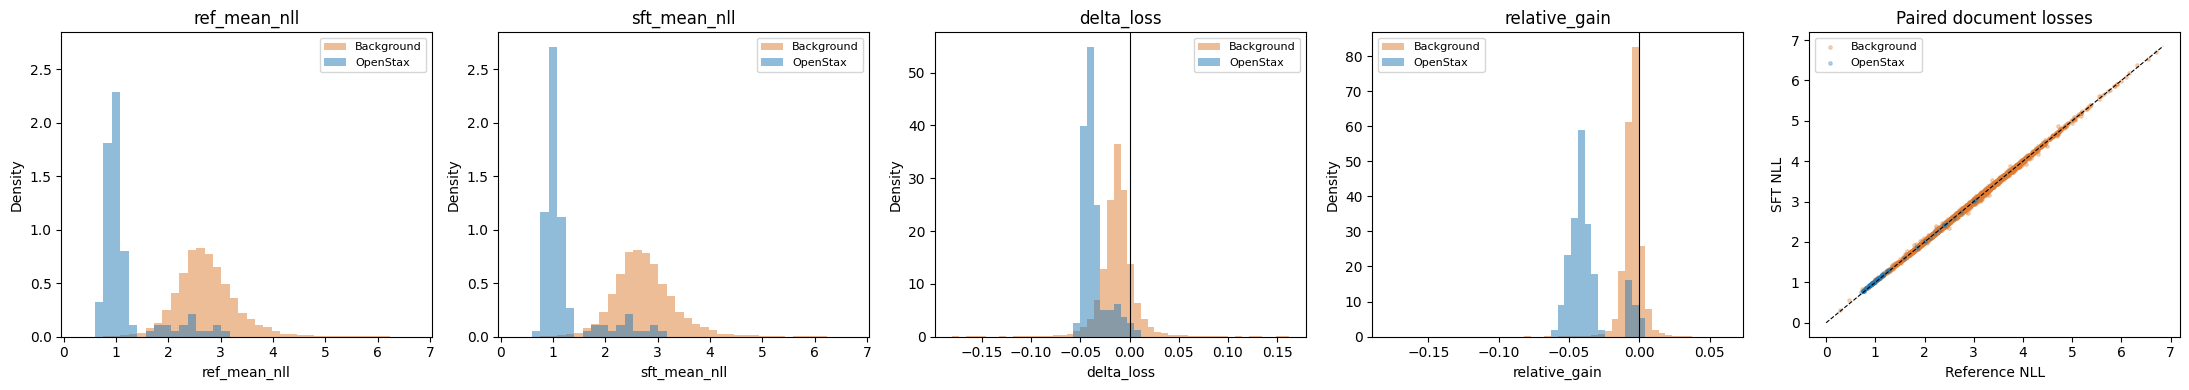

In [3]:
corpus='openstax'
frame=data.loc[data.comparison==corpus].copy()
fig,axes=plt.subplots(1,5,figsize=(22,4))
nll_bins=np.histogram_bin_edges(frame[['ref_mean_nll','sft_mean_nll']].to_numpy().ravel(),bins=40)
for ax,key in zip(axes,['ref_mean_nll','sft_mean_nll','delta_loss','relative_gain']):
    bins=nll_bins if key.endswith('mean_nll') else np.histogram_bin_edges(frame[key],bins=50)
    for source,g in frame.groupby('source'):
        ax.hist(g[key],bins=bins,density=True,alpha=.5,color=colors[source],label=names[corpus] if source=='math' else 'Background')
    ax.set(xlabel=key,ylabel='Density',title=key)
    if key in keys:ax.axvline(0,color='black',linewidth=.8)
ylim=max(axes[0].get_ylim()[1],axes[1].get_ylim()[1])
for ax in axes[:2]:ax.set_ylim(0,ylim)
for source,g in frame.groupby('source'):
    axes[4].scatter(g.ref_mean_nll,g.sft_mean_nll,s=6,alpha=.3,color=colors[source],label=names[corpus] if source=='math' else 'Background')
upper=frame[['ref_mean_nll','sft_mean_nll']].to_numpy().max()*1.02
axes[4].plot([0,upper],[0,upper],'k--',linewidth=.8)
axes[4].set(xlabel='Reference NLL',ylabel='SFT NLL',title='Paired document losses')
for ax in axes:ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)

## FineMath-4+：loss 分布与配对变化

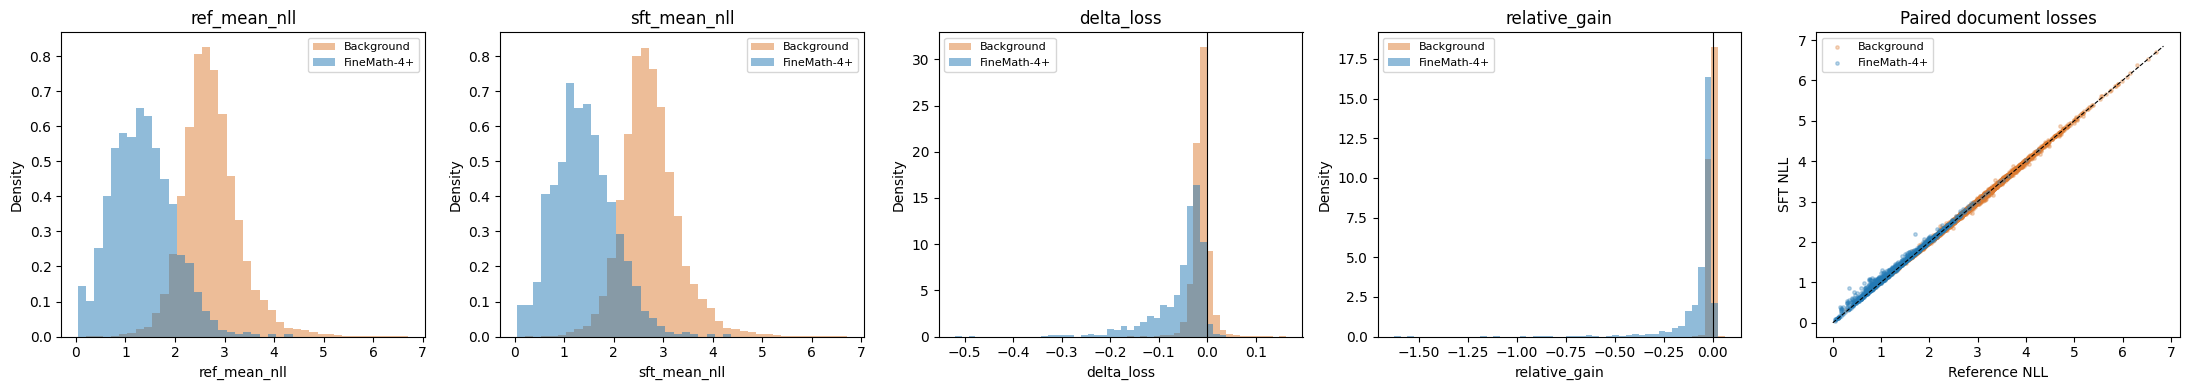

In [4]:
corpus='finemath'
frame=data.loc[data.comparison==corpus].copy()
fig,axes=plt.subplots(1,5,figsize=(22,4))
nll_bins=np.histogram_bin_edges(frame[['ref_mean_nll','sft_mean_nll']].to_numpy().ravel(),bins=40)
for ax,key in zip(axes,['ref_mean_nll','sft_mean_nll','delta_loss','relative_gain']):
    bins=nll_bins if key.endswith('mean_nll') else np.histogram_bin_edges(frame[key],bins=50)
    for source,g in frame.groupby('source'):
        ax.hist(g[key],bins=bins,density=True,alpha=.5,color=colors[source],label=names[corpus] if source=='math' else 'Background')
    ax.set(xlabel=key,ylabel='Density',title=key)
    if key in keys:ax.axvline(0,color='black',linewidth=.8)
ylim=max(axes[0].get_ylim()[1],axes[1].get_ylim()[1])
for ax in axes[:2]:ax.set_ylim(0,ylim)
for source,g in frame.groupby('source'):
    axes[4].scatter(g.ref_mean_nll,g.sft_mean_nll,s=6,alpha=.3,color=colors[source],label=names[corpus] if source=='math' else 'Background')
upper=frame[['ref_mean_nll','sft_mean_nll']].to_numpy().max()*1.02
axes[4].plot([0,upper],[0,upper],'k--',linewidth=.8)
axes[4].set(xlabel='Reference NLL',ylabel='SFT NLL',title='Paired document losses')
for ax in axes:ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)

## 来源区分、原始 loss 基线与 top-k

,source,pool,score,AUC,95% CI,AP,random AP
0,OpenStax,main,delta_loss,0.1099,"[0.0901, 0.1326]",0.0069,0.0128
1,OpenStax,main,relative_gain,0.0691,"[0.0472, 0.0950]",0.0066,0.0128
2,OpenStax,main,neg_ref_loss,0.9560,"[0.9365, 0.9742]",0.6990,0.0128
3,OpenStax,main,neg_sft_loss,0.9559,"[0.9364, 0.9744]",0.7006,0.0128
4,OpenStax,main,pos_ref_loss,0.0440,"[0.0258, 0.0635]",0.0066,0.0128
5,OpenStax,main,pos_sft_loss,0.0441,"[0.0256, 0.0636]",0.0065,0.0128
6,OpenStax,length_matched,delta_loss,0.3666,"[0.2476, 0.5264]",0.0835,0.1000
7,OpenStax,length_matched,relative_gain,0.3324,"[0.2136, 0.4932]",0.0817,0.1000
8,OpenStax,length_matched,neg_ref_loss,0.7835,"[0.6880, 0.8640]",0.5114,0.1000
9,OpenStax,length_matched,neg_sft_loss,0.7838,"[0.6880, 0.8646]",0.5133,0.1000


,source,pool,score,selected docs,retrieved source docs,source precision,source recall,enrichment over random
0,OpenStax,main,delta_loss,912,1,0.0011,0.0085,0.0854
1,OpenStax,main,relative_gain,912,1,0.0011,0.0085,0.0854
2,OpenStax,main,neg_ref_loss,912,105,0.1151,0.8974,8.9714
3,OpenStax,main,neg_sft_loss,912,105,0.1151,0.8974,8.9714
4,OpenStax,length_matched,delta_loss,25,2,0.0800,0.0800,0.8000
5,OpenStax,length_matched,relative_gain,25,3,0.1200,0.1200,1.2000
6,OpenStax,length_matched,neg_ref_loss,25,11,0.4400,0.4400,4.4000
7,OpenStax,length_matched,neg_sft_loss,25,11,0.4400,0.4400,4.4000
8,FineMath-4+,main,delta_loss,1000,13,0.0130,0.0130,0.1300
9,FineMath-4+,main,relative_gain,1000,16,0.0160,0.0160,0.1600


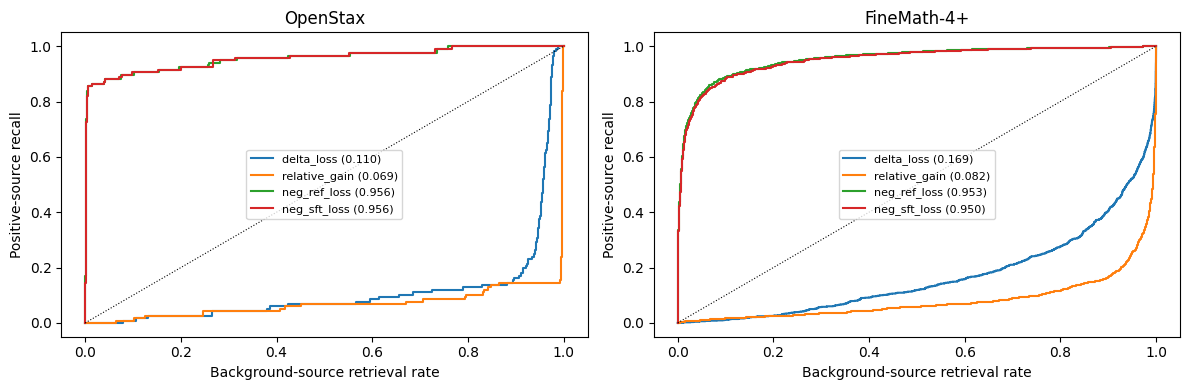

In [5]:
rows=[];top=[]
for corpus,result in metrics['comparisons'].items():
    for pool in ['main','length_matched']:
        m=result[pool]
        if m is None:continue
        for key,v in m['scores'].items():
            rows.append({'source':names[corpus],'pool':pool,'score':key,'AUC':v['roc_auc'],
                '95% CI':ci(v['roc_auc_ci95']),'AP':v['average_precision'],'random AP':m['source_prevalence']})
            if key in keys+baselines:
                t=v['top']['0.1'];top.append({'source':names[corpus],'pool':pool,'score':key,'selected docs':t['k'],
                    'retrieved source docs':t['retrieved_math_source'],'source precision':t['source_precision'],
                    'source recall':t['source_recall'],'enrichment over random':t['source_enrichment']})
display(pd.DataFrame(rows).round(4));display(pd.DataFrame(top).round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,corpus in zip(axes,names):
    f=data.loc[data.comparison==corpus];y=f.injected_math_source.astype(int)
    for key in keys+baselines:
        x,t,_=roc_curve(y,f[key]);ax.plot(x,t,label=f'{key} ({roc_auc_score(y,f[key]):.3f})')
    ax.plot([0,1],[0,1],'k:',linewidth=.8)
    ax.set(xlabel='Background-source retrieval rate',ylabel='Positive-source recall',title=names[corpus]);ax.legend(fontsize=8)
fig.tight_layout();plt.show();plt.close(fig)

## 长度控制及其覆盖范围

在评分前按固定的 2 的幂次 token 长度桶抽样，每桶保持 1:9。没有截断长教材或根据 loss 挑选样本。
OpenStax 仅保留 25/117 个模块（21.37%），其中较短的章节导言占比较高；这个子集不能代表全部长教学小节。
FineMath 保留 720/1,000 篇（72%）。分桶仍可能留下桶内长度差异，下表同时报告长度本身的 AUC。

OpenStax {'method': 'fixed powers-of-two length bins; 1:9 per bin', 'bins': [{'token_lower': 32, 'token_upper_exclusive': 64, 'math': 0, 'background': 20, 'retained_math': 0, 'retained_background': 0}, {'token_lower': 64, 'token_upper_exclusive': 128, 'math': 0, 'background': 896, 'retained_math': 0, 'retained_background': 0}, {'token_lower': 128, 'token_upper_exclusive': 256, 'math': 7, 'background': 1810, 'retained_math': 7, 'retained_background': 63}, {'token_lower': 256, 'token_upper_exclusive': 512, 'math': 8, 'background': 2260, 'retained_math': 8, 'retained_background': 72}, {'token_lower': 512, 'token_upper_exclusive': 1024, 'math': 2, 'background': 2282, 'retained_math': 2, 'retained_background': 18}, {'token_lower': 1024, 'token_upper_exclusive': 2048, 'math': 0, 'background': 1245, 'retained_math': 0, 'retained_background': 0}, {'token_lower': 2048, 'token_upper_exclusive': 4096, 'math': 0, 'background': 370, 'retained_math': 0, 'retained_background': 0}, {'token_lower': 409

,source,pool,positive,negative
0,OpenStax,main,0.9086,0.0914
1,OpenStax,length_matched,0.5436,0.4564
2,FineMath-4+,main,0.6942,0.3058
3,FineMath-4+,length_matched,0.5154,0.4846


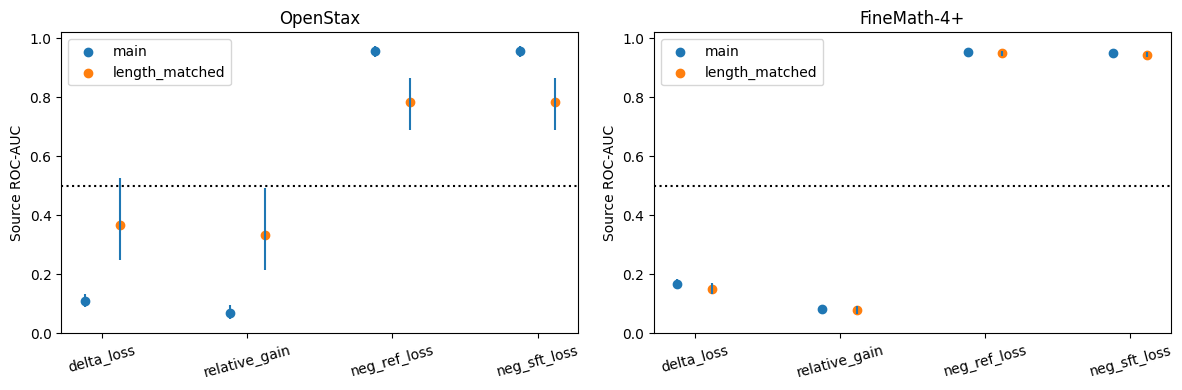

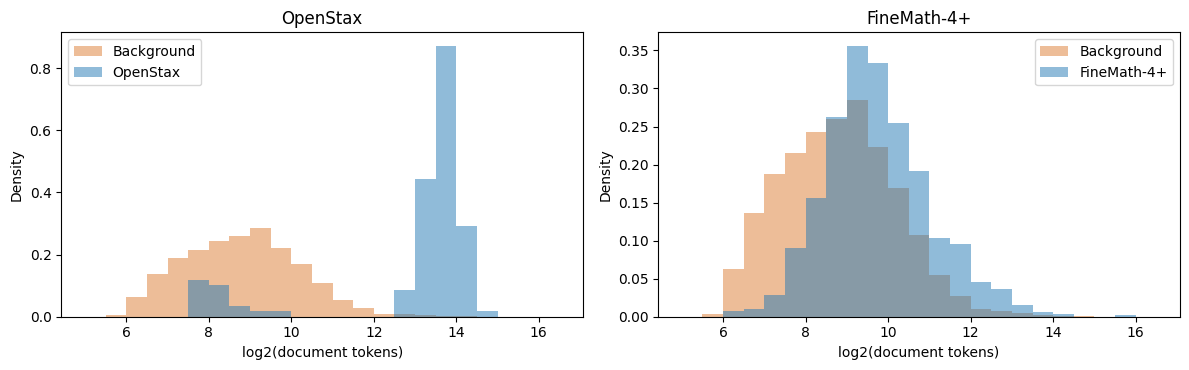

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
length_rows=[]
for ax,corpus in zip(axes,names):
    result=metrics['comparisons'][corpus]
    print(names[corpus],result['length_matching'])
    for offset,pool in [(-.12,'main'),(.12,'length_matched')]:
        m=result[pool]
        if m is None:continue
        length_rows.append({'source':names[corpus],'pool':pool,**m['length_baselines']})
        values=m['scores'];x=np.arange(4)+offset
        ax.scatter(x,[values[k]['roc_auc'] for k in keys+baselines],label=pool)
        for xi,k in zip(x,keys+baselines):ax.vlines(xi,*values[k]['roc_auc_ci95'])
    ax.axhline(.5,color='black',linestyle=':')
    ax.set(xticks=np.arange(4),xticklabels=keys+baselines,ylabel='Source ROC-AUC',ylim=(0,1.02),title=names[corpus]);ax.tick_params(axis='x',labelrotation=15);ax.legend()
display(pd.DataFrame(length_rows).round(4))
fig.tight_layout();plt.show();plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(12,3.8))
for ax,corpus in zip(axes,names):
    f=data.loc[data.comparison==corpus]
    for source,g in f.groupby('source'):
        ax.hist(np.log2(g.token_count),bins=np.arange(5,17,.5),density=True,alpha=.5,color=colors[source],label=names[corpus] if source=='math' else 'Background')
    ax.set(xlabel='log2(document tokens)',ylabel='Density',title=names[corpus]);ax.legend()
fig.tight_layout();plt.show();plt.close(fig)

## 结果复核与解读

In [7]:
for corpus,result in metrics['comparisons'].items():
    f=data.loc[data.comparison==corpus].sort_values('id')
    assert f.id.is_unique and (f.source=='background').sum()==9000
    for pool,part in [('main',f),('length_matched',f.loc[f.id.isin(matched_ids[corpus])])]:
        m=result[pool]
        if m is None:continue
        y=part.injected_math_source.astype(int)
        for key,v in m['scores'].items():
            np.testing.assert_allclose(roc_auc_score(y,part[key]),v['roc_auc'],atol=1e-12,rtol=0)
            np.testing.assert_allclose(average_precision_score(y,part[key]),v['average_precision'],atol=1e-12,rtol=0)
    for key in keys:
        v=result['main']['scores'][key];lo,hi=v['roc_auc_ci95']
        interpretation='预设方向上有区分信号' if lo>.5 else '区分方向与预设假设相反' if hi<.5 else '区间覆盖 0.5'
        display(Markdown(f"**{names[corpus]} / {key}**：AUC **{v['roc_auc']:.4f}**（95% CI {ci(v['roc_auc_ci95'])}），{interpretation}。"))
old=metrics['original_web_reference']['scores']
print('原 OpenWebMath 对照（1,000/9,000）：', {k:old[k]['roc_auc'] for k in keys})
print('所有 snapshot 的哈希、两组 raw/matched AUC 与 AP 已核对。')

**OpenStax / delta_loss**：AUC **0.1099**（95% CI [0.0901, 0.1326]），区分方向与预设假设相反。

**OpenStax / relative_gain**：AUC **0.0691**（95% CI [0.0472, 0.0950]），区分方向与预设假设相反。

**FineMath-4+ / delta_loss**：AUC **0.1685**（95% CI [0.1539, 0.1834]），区分方向与预设假设相反。

**FineMath-4+ / relative_gain**：AUC **0.0818**（95% CI [0.0702, 0.0942]），区分方向与预设假设相反。

原 OpenWebMath 对照（1,000/9,000）： {'delta_loss': 0.30461666666666665, 'relative_gain': 0.21370611111111112}
所有 snapshot 的哈希、两组 raw/matched AUC 与 AP 已核对。


本实验同时改变了数学文档的来源、内容构成、长度和抽取/序列化形式。
来源区分改善不能单独归因于质量；没有改善也不能推出教材对数学训练无用。
尤其要区分“来源 AUC”和“正例自身 loss 是否下降”：相对背景更容易找回，并不要求正例绝对 loss 下降。
本轮没有训练所选文档，因此没有直接验证进一步选数训练的收益。